# Demo of diffusion-based FWI on Overthrust model (step3)

## Description
This notebook implements DMFWI using Deepwave and PyTorch.  
It is designed for generating synthetic seismic data, performing wave propagation simulation, and updating velocity models through gradient-based optimization.

## Workflow
1. Import required libraries
2. Load velocity model and acquisition parameters
3. Generate source wavelets and geometry
4. Run forward simulation
5. Compute loss between observed and simulated data
6. Update model parameters
7. Visualize results

## Author
Chao Li

## Date
2026-04-07

In [1]:
import time
import torch
from torchvision import transforms as T, utils
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import io
import hydra
from omegaconf import DictConfig
import os
import sys
import deepwave
from deepwave import scalar
from torch.optim import Adam
from torchaudio.functional import biquad
from scipy.ndimage import gaussian_filter
from scipy.signal import butter
from torch import optim
import sys
from utils.utils import *
from diffusionreg import myprediff
from denoising_diffusion_pytorch.denoising_diffusion_pytorch_only_over import num_to_groups, Trainer, Unet, GaussianDiffusion
from hydra import initialize, compose
from omegaconf import DictConfig

/home/lcgeo/anaconda3/envs/lcgeopy/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dx        = 30                 # step interval along x/z direction
dt        = 0.003                # time interval (e.g., 3ms)
num_dims  = 2                     # dimension of velocity model
nz        = 100                  # model shape of z dimension (depth) Marmousi2
ny        = 401                   # model shape of y dimension Marmousi2
vmodel_dim = np.array([nz, ny])

total_t   = 6                      # totle sampling time (unit: s)
nt        = int(total_t / dt)       # number of time sampling points
num_shots = 66                  # nunmber of shots
num_sources_per_shot = 1            # number of sources per shot
num_receivers_per_shot = 400        # number of receivers per shot
#source_spacing = np.floor(dx * ny / (num_shots+1))                         # space intervel between neigbouring sources
#receiver_spacing = np.floor(dx * ny / (num_receivers_per_shot +1))         # space intervel between neigbouring receivers

source_spacing=6 ###this is the number of grid not the real distance 6:dx*6=150m
receiver_spacing=1 ###this is the number of grid not the real distance 1=25m

source_depth = 1                # the index depth of sources, default is 0
receiver_depth = 1              # the index depths of receivers, default is 0
order          = 8              # precision order of finite difference in space domain

fwi_lr            = 2       # learning rate for updating the model.
fwi_batch         = num_shots     # number of batches for FWI.
fwi_num_epochs    = 20   # number of FWI iteration test
survey_pad = None
savepoch = 50                 # Saving models each 50 FWI iterations
first_source=0
n_sources_per_shot=1
first_receiver=0

diffreg=1          ####whther use diffusion regularization
nwater=6           #### thickness of water layer

Text(0.5, 1.0, 'Initial')

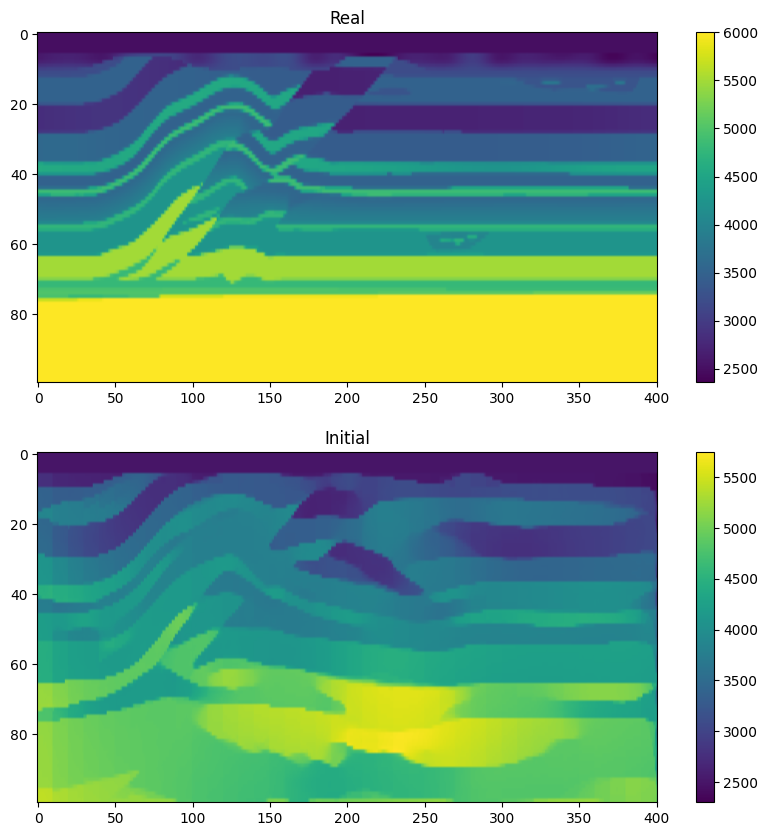

In [3]:
torch.backends.cudnn.enabled = True     ######activate CUDNN
torch.backends.cudnn.benchmark = True   ######select the optimal optimization method

cuda_available = torch.cuda.is_available()
device = torch.device("cuda:0" if cuda_available else "cpu")

directadd=os.path.join(os.getcwd())


data_path = directadd+'/data_overall/myover_100_401.bin'
initsafile = directadd+'/data_overall/mar_big_initsource.mat'
initfile = directadd+'/results/overnpy/dfwiover_step2.npy'


fwi_resultnpy = directadd+'/results/overnpy/'


# Loading the true model
model_true = loadtruemodel(data_path, num_dims, vmodel_dim).to(device)


model= np.load(initfile)
model[0:nwater,:]=2500

model_init = model

model = torch.tensor(model_init).float().to(device) 

model.requires_grad = True 
model = torch.nn.Parameter(model)

plt.figure(figsize=(10,10))
plt.subplot(2,1,1)
plt.imshow(model_true.detach().cpu().numpy(),aspect='auto')
plt.colorbar()
plt.title("Real")
plt.subplot(2,1,2)
plt.imshow(model.detach().cpu().numpy(),aspect='auto')
plt.colorbar()
plt.title("Initial")



Text(0.5, 1.0, 'Observed shots')

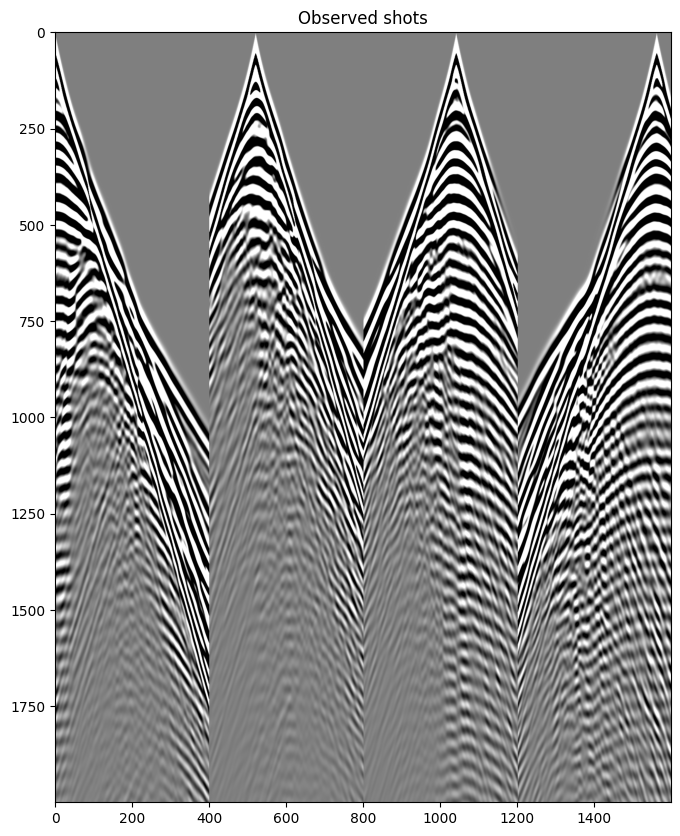

In [4]:
# Creating source and reciver locations

source_locations = torch.zeros(
            num_shots, n_sources_per_shot, 2, dtype=torch.long, device=device
        )
source_locations[..., 1] = source_depth

source_locations[:, 0, 0] = torch.arange(num_shots) * source_spacing + first_source



receiver_locations = torch.zeros(
            num_shots, num_receivers_per_shot, 2, dtype=torch.long, device=device
        )
receiver_locations[..., 1] = receiver_depth
receiver_locations[:, :, 0] = (
            (torch.arange(num_receivers_per_shot) * receiver_spacing + first_receiver).repeat(num_shots, 1)
        )




# Setup source amplitudes

source_amplitudes_init, source_amplitudes_true = loadinitsource(initsafile,device)
source = source_amplitudes_init.repeat(1,num_shots, num_sources_per_shot).permute(1,0,2).permute(0,2,1)


out = deepwave.scalar(model_true.T, dx, dt, source_amplitudes=source,
             source_locations=source_locations,
             receiver_locations=receiver_locations,
             accuracy=8,         
             pml_width=[10,10,0,10])

rcv_amps_true = out[-1].permute(2,0,1)

plt.figure(figsize=(12,10))
plt.imshow(rcv_amps_true[:,::20,:].detach().cpu().numpy().reshape(rcv_amps_true[:,::20,:].shape[0],rcv_amps_true[:,::20,:].shape[1]*rcv_amps_true[:,::20,:].shape[2]),cmap='gray',vmin=-1,vmax=1)
plt.title('Observed shots')



In [5]:
############function for diffusion regularization
def myreg(tmodel,ws1,ws2,tartime,pmin,pmax):
    with initialize(config_path="config",version_base=None):
         cfg = compose(config_name="config")
         
    modelr = myprediff(cfg, tmodel,ws1,ws2,tartime,pmin,pmax)
   
    return modelr

pmin=2300    ####minimum of velocity
pmax=6000    ####maximum of velocity
from torchsummary import summary

### optimizer for the velocity model
optimizer = optim.Adam([{'params': model, 'lr':fwi_lr, 'betas':(0.5, 0.9), 'eps':1e-8, 'weight_decay':0}])  #####The model here is initial model

SNR = 0.0
SSIM = 0.0
Loss = 0.0
ERROR = 0.0

#######################step 6

import torch.nn.functional as F

t_start = time.time()

# number of shots per batch
num_shots_per_batch = int(num_shots / fwi_batch)  #####30/30

for i in range(fwi_num_epochs):
    # initialization of the loss
    epoch_loss = 0.0

    for it in range(fwi_batch):
    
        iteration = i*fwi_batch+it+1
        # Set both optimizers to zero grad.
        optimizer.zero_grad()
     
        batch_src_amps = source_amplitudes_init.repeat(1, num_shots_per_batch, 1).permute(1,0,2).permute(0,2,1)

        batch_rcv_amps_true = rcv_amps_true[:,it::fwi_batch].to(device)
        

        
        batch_x_s = source_locations[it::fwi_batch].to(device)
        batch_x_r = receiver_locations[it::fwi_batch].to(device)

        

        outpre = deepwave.scalar(model.T, dx, dt, source_amplitudes=batch_src_amps,
             source_locations=batch_x_s,
             receiver_locations=batch_x_r,
             accuracy=8,         
             pml_width=[10,10,0,10])

        batch_rcv_amps_pred = outpre[-1].permute(2,0,1)
            
        d_real = (batch_rcv_amps_true).permute(1,0,2)
  
        
        
        d_real = d_real.unsqueeze(1)
        
              
              
        d_fake = (batch_rcv_amps_pred).permute(1,0,2)
    
        d_fake = d_fake.unsqueeze(1)
        

               
        
        loss =   F.pairwise_distance(d_fake, d_real, keepdim = True).mean()  
        
      
       
        epoch_loss += loss.item()
        loss.backward()
     
        
        # Clips gradient value of model
        torch.nn.utils.clip_grad_value_(model,1e3) 
        
       

        model.grad[0:nwater,:]=0 
        # Update the velocity model
        optimizer.step()
        # clip the model value that keep the minimum value is larger than 0
    
        
        model.data=torch.clamp(model.data,min=2200,max=6100)
   
    ########add diffusion regularization here
    if i==fwi_num_epochs-1 and diffreg==1:
         ws1=10
         ws2=10
         tartime=100
         model=myreg(model,ws1,ws2,tartime,pmin,pmax).clone()
         model.requires_grad = True 

    
    Loss = np.append(Loss, epoch_loss / fwi_batch)

    # compute the SNR and SSIM
    snr = ComputeSNR(model.detach().cpu().numpy(),  
              model_true.detach().cpu().numpy())
    SNR = np.append(SNR, snr)

    ssim = ComputeSSIM(model.detach().cpu().numpy(), \
              model_true.detach().cpu().numpy())
    SSIM = np.append(SSIM, ssim)

    rerror = ComputeRE(model.detach().cpu().numpy(), \
              model_true.detach().cpu().numpy())
    ERROR = np.append(ERROR, rerror)

    print('Epoch:', i+1, 'Loss: ', epoch_loss / fwi_batch, 'SNR:', snr, 'SSIM:', ssim.cpu().detach().cpu().numpy())

                          
                        

# Estimating the FWI time
t_end = time.time()
elapsed_time = t_end - t_start
print('Running complete in {:.0f}m  {:.0f}s' .format(elapsed_time //60 , elapsed_time % 60))


Epoch: 1 Loss:  21.081479188167688 SNR: 17.050919 SSIM: 0.3801654
Epoch: 2 Loss:  17.97292612538193 SNR: 17.061676 SSIM: 0.3919238
Epoch: 3 Loss:  16.360062180143416 SNR: 17.077646 SSIM: 0.4025368
Epoch: 4 Loss:  15.311184420730129 SNR: 17.10345 SSIM: 0.41108215
Epoch: 5 Loss:  14.591636571017178 SNR: 17.137344 SSIM: 0.41828847
Epoch: 6 Loss:  14.049611640698982 SNR: 17.174934 SSIM: 0.42444572
Epoch: 7 Loss:  13.61174436049028 SNR: 17.214409 SSIM: 0.4297218
Epoch: 8 Loss:  13.240763953237822 SNR: 17.254974 SSIM: 0.43447155
Epoch: 9 Loss:  12.914116743839148 SNR: 17.296263 SSIM: 0.43875536
Epoch: 10 Loss:  12.616568074081883 SNR: 17.338034 SSIM: 0.44265404
Epoch: 11 Loss:  12.337726318474973 SNR: 17.38015 SSIM: 0.44637638
Epoch: 12 Loss:  12.070430661692765 SNR: 17.42254 SSIM: 0.44987598
Epoch: 13 Loss:  11.809651013576623 SNR: 17.465193 SSIM: 0.45328435
Epoch: 14 Loss:  11.551577127341067 SNR: 17.507923 SSIM: 0.45657474
Epoch: 15 Loss:  11.292916023369992 SNR: 17.550573 SSIM: 0.4598358

sampling loop time step L0: 100%|██████████| 100/100 [00:00<00:00, 271.58it/s]


1


sampling loop time step L0: 100%|██████████| 100/100 [00:00<00:00, 1833.46it/s]


2


...

30


sampling loop time step L0: 100%|██████████| 100/100 [00:00<00:00, 1835.98it/s]


31


sampling loop time step L0: 100%|██████████| 100/100 [00:00<00:00, 1839.10it/s]


Epoch: 20 Loss:  9.924315683769457 SNR: 18.106913 SSIM: 0.4234806
Running complete in 1m  33s


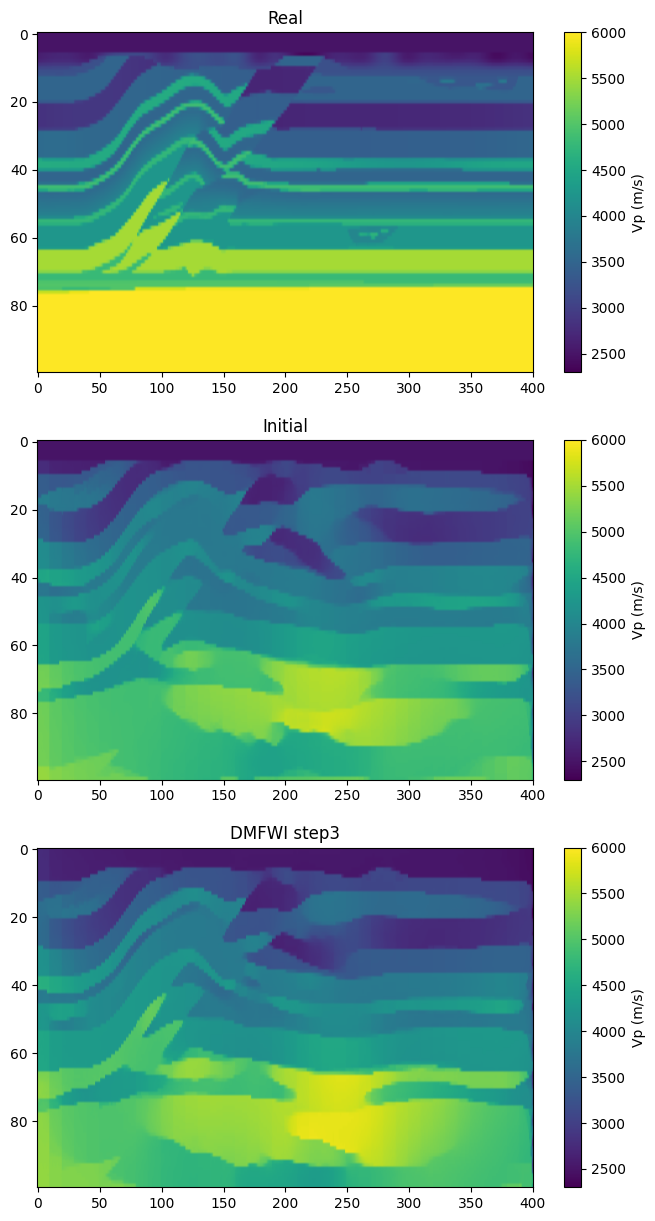

In [6]:
plt.figure(figsize=(8,15))
plt.subplot(3,1,1)
plt.imshow(model_true.detach().cpu().numpy(),aspect='auto',vmin=pmin,vmax=pmax)
plt.colorbar(label="Vp (m/s)")
plt.title("Real")
plt.subplot(3,1,2)
plt.imshow(model_init,aspect='auto',vmin=pmin,vmax=pmax)
plt.colorbar(label="Vp (m/s)")
plt.title("Initial")
plt.subplot(3,1,3)
plt.imshow(model.detach().cpu().numpy(),aspect='auto',vmin=pmin,vmax=pmax)
plt.colorbar(label="Vp (m/s)")
plt.title("DMFWI step3")

outnpy='dfwiover_step3.npy'

np.save(fwi_resultnpy+ outnpy, model.cpu().data.numpy())      # save for step4